# 09 - Interpolação
Vamos aprender sobre como usar aproximação de funções que permite construir um novo conjunto de dados a partir de um conjunto discreto de dados pontuais previamente conhecidos.

Crie uma nova branch (versão) do repositório:

```bash
git branch semana9
```

Faça o checkout nessa nova branch:

```bash
git checkout semana9
```

<hr />

## Atividade 1
Escreva os métodos de Newton, Lagrange, polinomial dentro do arquivo $utils/algoritmos.py$.

In [ ]:
import numpy as np


def newton_coef(x, y):
    n = len(x)
    a = np.array(y, dtype=float).copy()
    for j in range(1, n):
        a[j:n] = (a[j:n] - a[j - 1 : n - 1]) / (x[j:n] - x[0 : n - j])
    return a


def newton(x, y):
    a = newton_coef(x, y)
    p = np.array([a[-1]])
    for k in range(len(a) - 2, -1, -1):
        p = np.convolve(p, np.array([1.0, -x[k]]))
        if len(p) > 0:
            p[-1] += a[k]
    return p


def lagrange_add(p, q):
    if len(q) > len(p):
        p, q = q, p
    off = len(p) - len(q)
    res = p[:]
    for i in range(len(q)):
        res[off + i] += q[i]
    return res


def lagrange_mul(p, q):
    deg = (len(p) - 1) + (len(q) - 1)
    res = [0.0] * (deg + 1)
    for i, a in enumerate(p):
        for j, b in enumerate(q):
            res[i + j] += a * b
    return res


def lagrange_scale(p, s):
    return [s * c for c in p]


def lagrange(x, y):
    n = len(x)
    p = [0.0]
    for i in range(n):
        m = [1.0]
        d = 1.0
        xi = x[i]
        for j in range(n):
            if j == i:
                continue
            m = lagrange_mul(m, [1.0, -x[j]])
            d *= xi - x[j]
        pi = lagrange_scale(m, y[i] / d)
        p = lagrange_add(p, pi)
    return p


def polinomial(x, y):
    n = len(x)
    V = np.vander(x, N=n, increasing=False)
    a = np.linalg.solve(V, y.astype(float))
    return a

Encontre o polinômio interpolador para o conjunto de pontos $[(-2, -47); (0, -3); (1, 4); (2, 41)]$, utilizando os métodos de Newton, Lagrange, polinomial e spline cúbica. Quais valores para x $[-1; 0.5; 1.5]$. Desenhe um gráfico com as funções econtradas numericamente.

**Resposta esperada:**

$$
f(x) = -47 
+ 22(x + 2)
- 5(x + 2)\,x
+ 5(x + 2)\,x\,(x - 1)
\tag{Newton}
$$

$$
f(x)=\sum_{i=0}^{3} y_i
\prod_{\substack{j=0 \\ j\ne i}}^{3}\frac{x-x_j}{x_i-x_j}
\quad\text{com}\quad
(x_0,y_0)=(-2,-47),\ (x_1,y_1)=(0,-3),\ (x_2,y_2)=(1,4),\ (x_3,y_3)=(2,41);
$$

$$
\begin{aligned}
f(x)=\;&
\frac{47}{24}\,x(x-1)(x-2)
\;-\;\frac{3}{4}\,(x+2)(x-1)(x-2)
\;-\;\frac{4}{3}\,(x+2)\,x\,(x-2)
\;+\;\frac{41}{8}\,(x+2)\,x\,(x-1).
\end{aligned}
$$

$$
f(x) \tag{Lagrange}
$$

$$
f(x) = -3 + 2x + 5x^3 \tag{polinomial}
$$

**Resultados:**

$$x = -1: \quad \text{Newton} = \text{Lagrange} = \text{polinomial} = -10; \quad \text{Spline} \approx -19.130435$$

$$x = 0.5: \quad \text{Newton} = \text{Lagrange} = \text{polinomial} = -1.375; \quad \text{Spline} \approx -1.211957$$

$$x = 1.5: \quad \text{Newton} = \text{Lagrange} = \text{polinomial} = 16.875; \quad \text{Spline} \approx 19.320652$$

x = -1.0:  N=-10.000000 | L=-10.000000 | P=-10.000000 | S=-19.130435
x =  0.5:  N=-1.375000 | L=-1.375000 | P=-1.375000 | S=-1.211957
x =  1.5:  N= 16.875000 | L= 16.875000 | P= 16.875000 | S= 19.320652


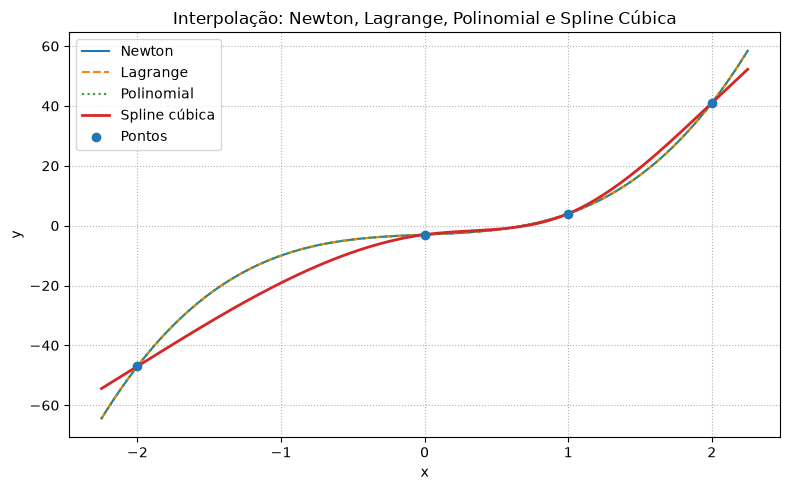

In [2]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Sobe um nível para a raiz do projeto e adiciona ao caminho do sistema
sys.path.append(os.path.abspath(os.path.join('..')))

from utils.algoritmos import (
    newton,
    lagrange,
    polinomial,
)


def plot(x, y):
    x_vals = np.linspace(min(x) - 0.25, max(x) + 0.25, 400)
    p = newton(x, y)
    yn = np.polyval(p, x_vals)
    p = lagrange(x, y)
    yl = np.polyval(p, x_vals)
    p = polinomial(x, y)
    yp = np.polyval(p, x_vals)
    spline = CubicSpline(x, y, bc_type="natural")
    ys = spline(x_vals)
    plt.figure(figsize=(8, 5))
    plt.plot(x_vals, yn, label="Newton")
    plt.plot(x_vals, yl, label="Lagrange", linestyle="--")
    plt.plot(x_vals, yp, label="Polinomial", linestyle=":")
    plt.plot(x_vals, ys, label="Spline cúbica", linewidth=2)
    plt.scatter(x, y, label="Pontos", zorder=5)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Interpolação: Newton, Lagrange, Polinomial e Spline Cúbica")
    plt.legend()
    plt.grid(True, which="both", linestyle=":")
    plt.tight_layout()
    plt.show()
    plt.close()


def main():
    x = np.array(
        [-2.0, 0.0, 1.0, 2.0],
        dtype=float,
    )
    y = np.array(
        [-47.0, -3.0, 4.0, 41.0],
        dtype=float,
    )

    xr = np.array(
        [-1.0, 0.5, 1.5],
        dtype=float,
    )

    p = newton(x, y)
    yn = np.polyval(p, xr)

    p = lagrange(x, y)
    yl = np.polyval(p, xr)

    p = polinomial(x, y)
    yp = np.polyval(p, xr)

    spline = CubicSpline(x, y, bc_type="natural")
    ys = spline(xr)

    for xi, n, l, p, s in zip(xr, yn, yl, yp, ys):
        print(f"x = {xi:>4}:  N={n: .6f} | L={l: .6f} | P={p: .6f} | S={s: .6f}")

    plot(x, y)


if __name__ == "__main__":
    main()

## Atividade 2
Encontre o polinômio interpolador para o conjunto de pontos $[(-1, 1.25); (0.5, 0.5); (1, 1.25); (1.25, 1.8125)]$, utilizando os métodos de Newton, Lagrange, polinomial e spline cúbica. Quais valores para x $[-0.5; 0; 0.25]$. Desenhe um gráfico com as funções econtradas numericamente.

**Resposta esperada:**

$$
f(x) = 0.25 + x^2 \tag{polinomial}
$$

**Resultados:**

$$x = -0.5:\quad \text{Newton} = \text{Lagrange} = \text{polinomial} = 0.5,\quad \text{Spline} \approx 0.5$$

$$x = 0:\quad \text{Newton} = \text{Lagrange} = \text{polinomial} = 0.25,\quad \text{Spline} \approx 0.25$$

$$x = 0.25:\quad \text{Newton} = \text{Lagrange} = \text{polinomial} = 0.3125,\quad \text{Spline} \approx 0.3125$$

## Atividade 3
A medição de alguns pontos de uma curva de saturação magnética, num processo de desmagnetização do ferrite $MnZn_3C_{15}$ é:

(a) Utilizando os métodos de Newton, Lagrange, polinomial e spline cúbica. Qual valor da indução magnética $(mT)$ para $H = 0 A/m$. Desenhe um gráfico com as funções econtradas numericamente.

$$
\begin{array}{c|cccc}
\text{H (A/m)} & -50 & -5 & 5 & 75 \\ \hline
\text{B (mT)} & -300 & -50 & 180 & 350
\end{array}
$$

**Resultado:**

$$H=0:\quad \text{Newton}=\text{Lagrange}=\text{Polinômio}= \mathbf{62.813852}\ \text{mT},\quad \text{Spline} \approx \mathbf{63.801020}\ \text{mT}$$

(b) Utilizando os métodos de Newton, Lagrange, polinomial e spline cúbica. Qual valor do campo magnético $(A/m)$ para $T = 8.5s$. Desenhe um gráfico com as funções econtradas numericamente.

$$
\begin{array}{c|ccccccccccc}
\text{T (s)} & 0 & 1 & 2 & 3 & 4 & 5 & 6 & 7 & 8 & 9 & 10 \\ \hline
\text{H (A/m)} & 80 & -60 & 40 & -30 & 20 & -10 & 5 & -2.5 & 1.25 & -0.625 & 0.3125
\end{array}
$$

**Resultado:**

$$T=8.5:\quad \text{Newton}=\text{Lagrange}=\text{Polinômio}= \mathbf{47.211610}\ \text{A/m},\quad \text{Spline} \approx \mathbf{1.057374}\ \text{A/m}$$

Os métodos de **Newton**, **Lagrange** e **Polinômio** geram o mesmo polinômio de grau $10$, o que provoca **oscilações acentuadas**, fenômeno conhecido como *Runge*. Assim, o valor interpolado se afasta dos vizinhos $H(8)=1.25$ e $H(9)=-0.625$. Já a **spline cúbica natural**, por ser uma aproximação **local e suave**, fornece resultados mais consistentes e fisicamente plausíveis entre os pontos.

## Versionando o código

Submeta a branch para o servidor:

```bash
git add .
git commit -m "Semana 9"
git push origin semana9
```